# Rainfall Prediction (Australia weather)

Will it rain tomorrow? Binary classification on daily weather observations from the weatherAUS dataset: about 142K days of Australian Bureau of Meteorology readings across 49 locations (2007 to 2017), as packaged in the R `rattle` library and the popular Kaggle copy. I load a public Hugging Face mirror of that file (`lowkeydev-ln/weatherAUS`).

There's a real class imbalance here (rainy days are about 22% of rows), so I'm watching recall on the positive class more than overall accuracy. A model that always predicts "no rain" hits 78% accuracy and is completely useless.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.pipeline import Pipeline

RNG = np.random.default_rng(11)
DATA_DIR = Path("../../data/rainfall")

In [2]:
csv_path = DATA_DIR / "weatherAUS.csv"
if not csv_path.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    pd.read_parquet("https://huggingface.co/datasets/lowkeydev-ln/weatherAUS/resolve/main/"
                    "data/train-00000-of-00001.parquet").to_csv(csv_path, index=False)

df = pd.read_csv(csv_path)
print("raw shape:", df.shape)
# the CSV has 24 columns. Keep a manageable numeric subset. RISK_MM is tomorrow's rainfall
# amount, so it would leak the target and stays out.
keep = ["MinTemp", "MaxTemp", "Rainfall", "Humidity9am", "Humidity3pm",
        "Pressure9am", "Pressure3pm", "WindGustSpeed", "Temp3pm", "RainTomorrow"]
df = df[keep].dropna()
df["RainTomorrow"] = (df["RainTomorrow"] == "Yes").astype(int)

print(f"after dropping rows with missing values: {df.shape}  |  positive rate: {df['RainTomorrow'].mean():.2%}")
df.head()

raw shape: (142193, 24)
after dropping rows with missing values: (119702, 10)  |  positive rate: 21.90%


,MinTemp,MaxTemp,Rainfall,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,WindGustSpeed,Temp3pm,RainTomorrow
0,13.4,22.9,0.6,71.0,22.0,1007.7,1007.1,44.0,21.8,0
1,7.4,25.1,0.0,44.0,25.0,1010.6,1007.8,44.0,24.3,0
2,12.9,25.7,0.0,38.0,30.0,1007.6,1008.7,46.0,23.2,0
3,9.2,28.0,0.0,45.0,16.0,1017.6,1012.8,24.0,26.5,0
4,17.5,32.3,1.0,82.0,33.0,1010.8,1006.0,41.0,29.7,0


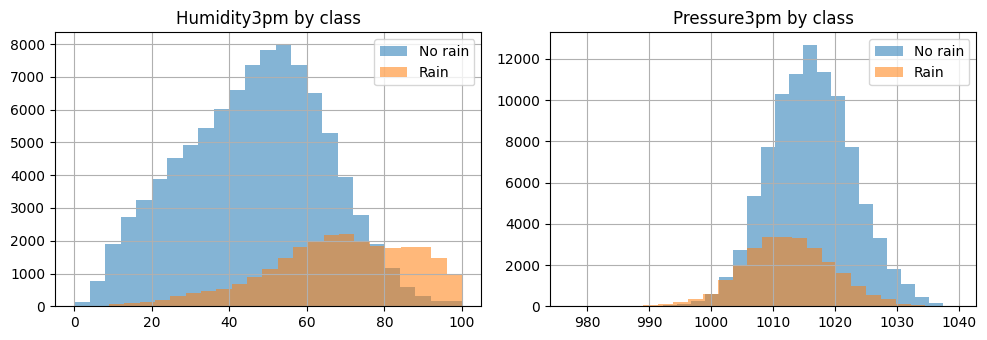

In [3]:
# quick look — humidity at 3pm is usually the strongest single signal
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for label, grp in df.groupby("RainTomorrow"):
    grp["Humidity3pm"].hist(bins=25, alpha=0.55, ax=ax[0], label=["No rain", "Rain"][label])
ax[0].set_title("Humidity3pm by class"); ax[0].legend()
if "Pressure3pm" in df.columns:
    for label, grp in df.groupby("RainTomorrow"):
        grp["Pressure3pm"].hist(bins=25, alpha=0.55, ax=ax[1], label=["No rain", "Rain"][label])
    ax[1].set_title("Pressure3pm by class"); ax[1].legend()
plt.tight_layout(); plt.show()

In [4]:
feature_cols = [c for c in df.columns if c != "RainTomorrow"]
X = df[feature_cols].values.astype(float)
y = df["RainTomorrow"].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=11)

# class_weight='balanced' on LR was a meaningful boost on the imbalanced version.
# RF is less sensitive because of its bootstrap sampling but I'm leaving it in for both.
models = {
    "LogReg": Pipeline([("sc", StandardScaler()),
                         ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "RandomForest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced", random_state=11, n_jobs=2),
}

for name, m in models.items():
    m.fit(X_tr, y_tr)
    proba = m.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(f"\n=== {name} ===")
    print(f"AUC: {roc_auc_score(y_te, proba):.3f}")
    print(classification_report(y_te, pred, digits=3))


=== LogReg ===
AUC: 0.860
              precision    recall  f1-score   support

           0      0.922     0.790     0.851     18697
           1      0.505     0.762     0.607      5244

    accuracy                          0.784     23941
   macro avg      0.714     0.776     0.729     23941
weighted avg      0.831     0.784     0.798     23941




=== RandomForest ===
AUC: 0.873
              precision    recall  f1-score   support

           0      0.902     0.896     0.899     18697
           1      0.639     0.653     0.646      5244

    accuracy                          0.843     23941
   macro avg      0.770     0.775     0.772     23941
weighted avg      0.844     0.843     0.844     23941



## Takeaways

On 119,702 complete rows (23,941 held out), the random forest gets ROC-AUC 0.873 and the class-balanced logistic regression 0.860. They trade off differently at the default threshold: LR catches more rainy days (recall 0.76) but half of its rain calls are wrong (precision 0.51), while RF is more balanced (recall 0.65, precision 0.64). Which one is "better" depends on whether a missed rainy day or a false alarm costs more.

The histograms above show the main signal: afternoon humidity is much higher before rainy days, and afternoon pressure is lower.

If I came back to this I'd add lag features (yesterday's rainfall, 3-day rolling humidity). Daily weather is autoregressive and a random split is technically cheating, because neighboring days from the same station land on both sides. A time-based split (train on earlier years, test on later ones) and a location-aware model would both be more honest, since Darwin and Hobart have very different base rates.